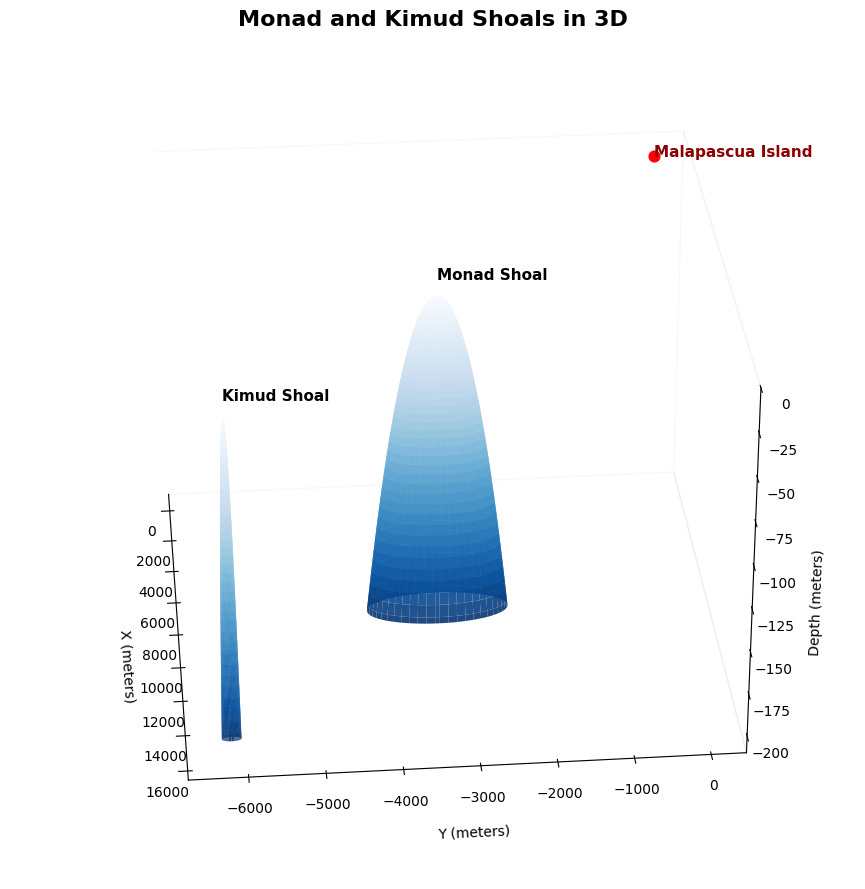

In [20]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from geopy.distance import geodesic
import math

# Geographic coordinates (latitude, longitude)
malapascua = (11.3358, 124.1156)
kimud = (11.280139, 124.255556)
monad = (11.306417, 124.189639)

# Compute distances in kilometers
d_malapascua_kimud = geodesic(malapascua, kimud).km * 1000  # in meters
d_malapascua_monad = geodesic(malapascua, monad).km * 1000
d_kimud_monad = geodesic(kimud, monad).km * 1000

# Convert lat/lon to local Cartesian (x, y) relative to Malapascua (0, 0)
def latlon_to_xy(origin, target):
    # Rough conversion using equirectangular projection
    lat1, lon1 = map(np.radians, origin)
    lat2, lon2 = map(np.radians, target)
    R = 6371000  # Radius of Earth in meters

    x = (lon2 - lon1) * np.cos((lat1 + lat2) / 2) * R
    y = (lat2 - lat1) * R
    return (x, y)

# Get Cartesian positions
kimud_xy = latlon_to_xy(malapascua, kimud)
monad_xy = latlon_to_xy(malapascua, monad)
malapascua_xy = (0, 0)

# Shoal parameters
shoals = {
    "Monad Shoal": {
        "radius": 955,
        "platform_depth": 15,
        "max_depth": 200,
        "position": monad_xy
    },
    "Kimud Shoal": {
        "radius": 127,
        "platform_depth": 15,
        "max_depth": 200,
        "position": kimud_xy
    }
}

# Plot setup
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
colormap = cm.Blues

# Plot each shoal
for name, shoal in shoals.items():
    r_vals = np.linspace(0, shoal["radius"], 100)
    theta = np.linspace(0, 2 * np.pi, 100)
    r, theta = np.meshgrid(r_vals, theta)

    z = shoal["platform_depth"] + (shoal["max_depth"] - shoal["platform_depth"]) * (r / shoal["radius"])**2
    x = r * np.cos(theta) + shoal["position"][0]
    y = r * np.sin(theta) + shoal["position"][1]

    z_norm = (z - z.min()) / (z.max() - z.min())
    facecolors = colormap(z_norm)

    ax.plot_surface(x, y, -z, facecolors=facecolors, linewidth=0, antialiased=True, shade=False, alpha=0.9)
    ax.text(shoal["position"][0], shoal["position"][1], -5, name, fontsize=11, color='black', weight='bold')

# Mark Malapascua Island
ax.scatter(*malapascua_xy, -5, color='red', s=60)
ax.text(*malapascua_xy, -5, "Malapascua Island", fontsize=11, color='darkred', weight='bold')

# Axis and view
ax.set_title('Monad and Kimud Shoals in 3D', fontsize=16, weight='bold')
ax.set_xlabel('X (meters)', labelpad=10)
ax.set_ylabel('Y (meters)', labelpad=10)
ax.set_zlabel('Depth (meters)', labelpad=10)
ax.set_zlim(-210, 0)
ax.view_init(elev=30, azim=-5)

# Aesthetic clean-up
ax.grid(False)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

plt.tight_layout()
plt.show()